# Load the data

In [35]:
RANDOM_STATE = 42

import pandas as pd
import numpy as np
from pathlib import Path
data_dir = Path("data")

X_test = data_dir / "X_test.csv"
y_train = data_dir / "y_train.csv"
X_train = data_dir / "X_train.csv"

X_test = pd.read_csv(X_test, index_col="id")
y_train = pd.read_csv(y_train, index_col="id")
X_train = pd.read_csv(X_train, index_col="id")

print(X_train.head())

               x0            x1           x2             x3          x4  \
id                                                                        
0.0  14168.823171  10514.380717  3316.149698   94230.695124  102.386606   
1.0  17757.037554           NaN  4101.016273   92959.527633         NaN   
2.0  14226.656663  11029.642499          NaN  124055.600561  100.542483   
3.0   8766.012436   7384.202998  2147.308418  100157.719990  104.855061   
4.0  13801.016418  13269.493652  3408.316953   92048.527786  103.759758   

             x5            x6            x7            x8         x9  ...  \
id                                                                    ...   
0.0   92.677127  11108.748199  10866.505510  10837.622093  10.227734  ...   
1.0   99.855168  10013.959449  10826.607494  10076.101597  11.436970  ...   
2.0   92.860892           NaN  10492.342868           NaN  10.810076  ...   
3.0  101.929026  10050.049932  10499.521099  10525.030989  10.092109  ...   
4.0   95.789

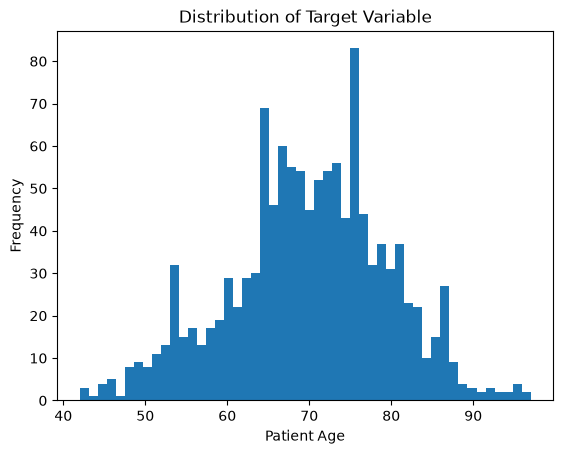

        y
id       
0.0  74.0
1.0  51.0
2.0  70.0
3.0  52.0
4.0  85.0


In [36]:
#have a look at the data
import matplotlib.pyplot as plt
plt.hist(y_train.values, bins=50)
plt.xlabel("Patient Age")
plt.ylabel("Frequency")
plt.title("Distribution of Target Variable")
plt.show()

print(y_train.head())


# 1. imputing missing values

First we impute nan values with the mean for each feature

In [37]:
#how many nan values are there?
print(f"Nan-values: {X_train.isna().sum().sum()}")
#which columns have nan values?
print(f"Columns with nan values: {X_train.columns[X_train.isna().any()]}")
print(f"Columns without nan values: {X_train.columns[~X_train.isna().any()]}")


Nan-values: 76902
Columns with nan values: Index(['x0', 'x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x9',
       ...
       'x822', 'x823', 'x824', 'x825', 'x826', 'x827', 'x828', 'x829', 'x830',
       'x831'],
      dtype='str', length=832)
Columns without nan values: Index([], dtype='str')


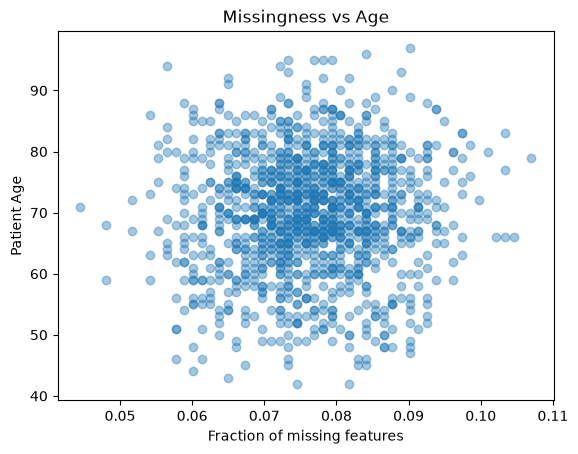

corr(missingness, age) = 0.0459


In [38]:
# One point per sample: row missing-rate vs age
row_missing = X_train.isna().mean(axis=1)
plt.scatter(row_missing, y_train["y"], alpha=0.4)
plt.xlabel("Fraction of missing features")
plt.ylabel("Patient Age")
plt.title("Missingness vs Age")
plt.show()
print(f"corr(missingness, age) = {row_missing.corr(y_train['y']):.4f}")


In [42]:
imputation_function = np.median

X_train.fillna(imputation_function(X_train), inplace=True)
X_test.fillna(imputation_function(X_test), inplace=True)
y_train.fillna(imputation_function(y_train), inplace=True)

f"Nan-values: {X_train.isna().sum().sum()}"


'Nan-values: 0'

Split train data for validation set

In [44]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.1, random_state=RANDOM_STATE)

print(f"Train data: {X_train.shape}, Validation data: {X_val.shape}")

Train data: (981, 832), Validation data: (109, 832)


# 2. Outlier detection
Next we build an outlier detection model to classify samples as outliers and eventually remove them

In [45]:
#outlier detection using isolation forest and guessing the contamination to be 5%

from sklearn.ensemble import IsolationForest
outlier_model = IsolationForest(contamination=0.05, random_state=RANDOM_STATE)
outlier_model.fit(X_train)
outlier_preds = outlier_model.predict(X_train)
isoforest_outlier_indices = set(np.where(outlier_preds == -1)[0])

print("Outlier indices:", isoforest_outlier_indices)

print(f"Number of outliers detected: {len(isoforest_outlier_indices)}")

Outlier indices: {np.int64(128), np.int64(258), np.int64(901), np.int64(390), np.int64(268), np.int64(269), np.int64(18), np.int64(403), np.int64(276), np.int64(22), np.int64(151), np.int64(918), np.int64(667), np.int64(28), np.int64(39), np.int64(688), np.int64(947), np.int64(52), np.int64(438), np.int64(439), np.int64(445), np.int64(704), np.int64(65), np.int64(450), np.int64(705), np.int64(835), np.int64(202), np.int64(586), np.int64(204), np.int64(77), np.int64(339), np.int64(469), np.int64(342), np.int64(344), np.int64(89), np.int64(219), np.int64(93), np.int64(349), np.int64(864), np.int64(481), np.int64(615), np.int64(232), np.int64(106), np.int64(876), np.int64(239), np.int64(623), np.int64(115), np.int64(122), np.int64(510)}
Number of outliers detected: 49


In [ ]:
# outlier detection using OneClassSVM

from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler



scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

svm_model = OneClassSVM(nu=0.01, kernel="rbf", gamma="scale")
svm_model.fit(X_train_scaled)
svm_preds = svm_model.predict(X_train_scaled)

print("SVM Outlier indices:", np.where(svm_preds == -1)[0])

svm_outlier_indices = set(np.where(svm_preds == -1)[0])

print(f"Number of outliers detected by SVM: {np.sum(svm_preds == -1)}")

# Comparing the two methods
common_outliers = isoforest_outlier_indices & svm_outlier_indices
print(f"Number of common outliers detected by both methods: {len(common_outliers)}")
print("Common outlier indices:", common_outliers)

SVM Outlier indices: [  16   30   32   56   70   72   88   91  142  168  180  207  211  214
  245  278  313  321  334  352  397  403  404  431  518  537  545  553
  570  574  583  616  622  631  633  635  681  694  731  732  741  755
  771  805  806  808  836  872  882  888  899  900  906  917  949  953
  972  990  994 1001 1038 1066 1081 1087 1102 1132 1135 1144 1205]
Number of outliers detected by SVM: 69
Number of common outliers detected by both methods: 19
Common outlier indices: {np.int64(900), np.int64(906), np.int64(397), np.int64(917), np.int64(278), np.int64(30), np.int64(805), np.int64(681), np.int64(694), np.int64(953), np.int64(321), np.int64(70), np.int64(583), np.int64(972), np.int64(1102), np.int64(731), np.int64(91), np.int64(882), np.int64(1144)}


In [ ]:
#removing outliers from the training data
X_train_cleaned = X_train.drop(index=X_train.index[list(common_outliers)])
y_train_cleaned = y_train.drop(index=y_train.index[list(common_outliers)])
print(f"Cleaned X_train shape: {X_train_cleaned.shape}, Cleaned y_train shape: {y_train_cleaned.shape}")

Cleaned X_train shape: (1193, 832), Cleaned y_train shape: (1193, 1)


# Feature selection

this step is harder than imagined, a new idea came to my mind:

1: select a subset of features randomly, train and score the predictions, as well as the features used

2: do it for another subset

3: mark the features which occur in higher scored subsets and use these for the final training (Monte Carlo aproach)

# Save the test results for online evaluation

In [31]:
from datetime import datetime

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

def final_training(model):
    model = model(**params)
    model.fit(X_selected, y_train_cleaned)
    return model

def save_test_predictions(model, model_name)-> Path:
    model = final_training(model)
    save_path = results_dir / f"test_{model_name}_{datetime.now().strftime('%Y%m%d_%H%M%S')}.csv"

    y_test_pred = model.predict(X_test[X_selected.columns])
    results_df = pd.DataFrame(y_test_pred, index=X_test.index, columns=["y"])
    assert (results_df.shape == (776, 1)), f"Unexpected shape: {results_df.shape}"
    results_df.to_csv(save_path)
    print(f"Test predictions saved to {save_path}")
    return save_path

print("Validation R2: ", model.score(X_val, y_val))

file = save_test_predictions(XGBRegressor, "xgboost")

NameError: name 'model' is not defined

In [ ]:
import subprocess

#submit predictions
def submit_predictions(file:Path, message:str) -> None:
    cmd = f'kaggle competitions submit -c eth-aml-2026-project-1 -f {file} -m "{message}"'
    res = subprocess.run(cmd, shell=True, check=True)
    print(res.stdout, res.stderr)

submit_msg = input("Enter submission message: ")
submit_predictions(file, submit_msg)

100%|██████████| 9.93k/9.93k [00:00<00:00, 25.4kB/s]


Successfully submitted to ETH AML 2025 Project 1None None
